# Step 4: Look at the daily files (QC)

This notebook belongs to the Geo-OBS manual, Session 6. It shows one day of one station and one component, so you can check that the data look like real seismic data and that the times are right.

**Input:** the daily files from `3_cut_daily_files.ipynb`:

```
<DATA_FOLDER>/<station>/DailyChunk/<station>_<component>_chunk0002_20260709T160000.segy
```

**What you get**

1. A **raster plot** of the whole day: one row per 60 s trace, loudness as color. Gaps (zeros), noisy hours and big events are easy to see here.
2. A **wiggle plot** of a few minutes around the time you choose.
3. A **spectrogram** of the same minutes: which frequencies carry the energy.
4. The raster and wiggle plots again after a **bandpass filter**.

You only have to change the cell **Settings**. Pick any time inside the day you want to look at: the notebook finds the right file by reading the trace times, not the file name.

## Settings

In [ ]:
from pathlib import Path

DATA_FOLDER = Path("/ur/path/to/data")   # folder that contains one folder per station
DAILY_FOLDER = "DailyChunk"                       # subfolder written by 3_cut_daily_files.ipynb

STATION = "0498"
COMPONENT = "z"                                   # "x", "y", "z" (geophones) or "h" (hydrophone)
TIME_LOCAL = "2026-07-09 20:30"                   # any time inside the day you want to see
UTC_OFFSET_HOURS = 2                              # the Trilobit records UTC; Svalbard summer time is UTC+2

ZOOM_MINUTES = 15                                 # wiggle plot and spectrogram: +/- minutes around TIME_LOCAL
FILTER_HZ = (3, 30)                               # bandpass filter: lowest and highest frequency

## Helper functions

In [2]:
import struct
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from datetime import datetime, timedelta
from scipy.signal import butter, sosfiltfilt, spectrogram

HEADER_BYTES = 3600


def trace_start_time(trace_header):
    year, day, hour, minute, second = struct.unpack(">5H", trace_header[156:166])
    millisecond, microsecond = struct.unpack(">2H", trace_header[168:172])
    return datetime(year, 1, 1) + timedelta(days=day - 1, hours=hour, minutes=minute, seconds=second,
                                            milliseconds=millisecond, microseconds=microsecond)


def file_info(path):
    """Samples per trace, sample interval [s], number of traces, start and end time (UTC). Reads only two trace headers."""
    with open(path, "rb") as f:
        f.seek(HEADER_BYTES)
        first = f.read(240)
        n_samples, dt_us = struct.unpack(">2H", first[114:118])
        trace_bytes = 240 + 4 * n_samples
        n_traces = (path.stat().st_size - HEADER_BYTES) // trace_bytes
        f.seek(HEADER_BYTES + (n_traces - 1) * trace_bytes)
        last = f.read(240)
    dt = dt_us / 1e6
    return n_samples, dt, n_traces, trace_start_time(first), trace_start_time(last) + timedelta(seconds=n_samples * dt)


def read_traces(path):
    """All samples of a file as an array (traces x samples)."""
    n_samples, dt, n_traces, start, end = file_info(path)
    trace = np.dtype([("header", "V240"), ("data", ">f4", n_samples)])
    traces = np.fromfile(path, dtype=trace, offset=HEADER_BYTES, count=n_traces)
    return traces["data"].astype(np.float32), dt, start


def find_daily_file(station, component, time_utc):
    files = sorted(p for p in (DATA_FOLDER / station / DAILY_FOLDER).glob(f"{station}_{component}_chunk*.segy")
                   if not p.name.startswith("._"))
    if not files:
        raise FileNotFoundError(f"No '{component}' files in {DATA_FOLDER / station / DAILY_FOLDER}")
    for path in files:
        *_, start, end = file_info(path)
        if start <= time_utc < end:
            return path
    raise FileNotFoundError(f"No file covers {time_utc} UTC. The files go from {file_info(files[0])[3]} "
                            f"to {file_info(files[-1])[4]} UTC.")

## Load the day

In [3]:
time_utc = datetime.strptime(TIME_LOCAL, "%Y-%m-%d %H:%M") - timedelta(hours=UTC_OFFSET_HOURS)
path = find_daily_file(STATION, COMPONENT, time_utc)
data, dt, start_utc = read_traces(path)
start_local = start_utc + timedelta(hours=UTC_OFFSET_HOURS)
trace_seconds = data.shape[1] * dt

# traces shown in the zoomed plots
center = int((time_utc - start_utc).total_seconds() // trace_seconds)
zoom_first = max(0, center - round(ZOOM_MINUTES * 60 / trace_seconds))
zoom_last = min(len(data), center + round(ZOOM_MINUTES * 60 / trace_seconds))
zoom_start_local = start_local + timedelta(seconds=zoom_first * trace_seconds)

empty = int((np.abs(data).max(axis=1) == 0).sum())
print(f"File: {path.name}")
print(f"{data.shape[0]} traces of {trace_seconds:.0f} s, sampling {1 / dt:.0f} Hz, "
      f"starts {start_local:%Y-%m-%d %H:%M} local time")
print(f"Traces without data (all zeros): {empty}")
print(f"Mean (offset) of the day: {data.mean():.0f}, standard deviation: {data.std():.0f}")
print(f"Zoom: traces {zoom_first} to {zoom_last - 1}")

File: 0498_z_chunk0002_20260709T160000.segy
1440 traces of 60 s, sampling 500 Hz, starts 2026-07-09 18:00 local time
Traces without data (all zeros): 0
Mean (offset) of the day: -41957, standard deviation: 5755
Zoom: traces 135 to 164


## Plot functions

- `raster_plot`: one row per 60 s trace, one pixel per second. The color is the RMS amplitude of that second on a log scale: dark = quiet, bright = loud, black rows = no data. The mean of every trace is removed first, because geophone data often have a large constant offset.
- `wiggle_plot`: every trace is divided by its own maximum, so the shape of quiet traces is visible too. Use the raster plot to compare amplitudes between traces.
- `spectrogram_plot`: power per frequency over time, in dB.

In [4]:
def raster_plot(data, dt, start_local, title):
    """One row per trace, one pixel per second. Color = RMS amplitude of that second (log scale)."""
    data = data - data.mean(axis=1, keepdims=True)          # remove the offset of every trace
    per_second = round(1 / dt)
    seconds = data.shape[1] // per_second
    rms = np.sqrt((data[:, :seconds * per_second].reshape(len(data), seconds, per_second) ** 2).mean(axis=2))
    low, high = np.percentile(rms[rms > 0], [1, 99.5]) if (rms > 0).any() else (1, 2)
    trace_seconds = data.shape[1] * dt
    fig, ax = plt.subplots(figsize=(14, 7))
    image = ax.imshow(rms, aspect="auto", cmap="magma", norm=LogNorm(low, high), interpolation="nearest",
                      extent=[0, trace_seconds, len(data), 0])
    rows = np.arange(0, len(data), round(3600 / trace_seconds))        # one label per hour
    ax.set_yticks(rows)
    ax.set_yticklabels([(start_local + timedelta(seconds=float(r * trace_seconds))).strftime("%d.%m. %H:%M") for r in rows])
    ax.set_xlabel("Time within the trace [s]")
    ax.set_ylabel("Start of the trace (local time)")
    ax.set_title(title)
    fig.colorbar(image, ax=ax, label="RMS amplitude per second")
    plt.show()


def wiggle_plot(data, dt, start_local, title):
    time = np.arange(data.shape[1]) * dt
    trace_seconds = data.shape[1] * dt
    fig, ax = plt.subplots(figsize=(14, 7))
    for row, trace in enumerate(data):
        peak = np.abs(trace).max() or 1.0
        ax.plot(time, row + 0.45 * trace / peak, color="black", linewidth=0.6)
    rows = np.arange(0, len(data), max(1, len(data) // 10))
    ax.set_yticks(rows)
    ax.set_yticklabels([(start_local + timedelta(seconds=float(r * trace_seconds))).strftime("%H:%M") for r in rows])
    ax.set_ylim(len(data), -1)
    ax.set_xlabel("Time within the trace [s]")
    ax.set_ylabel("Start of the trace (local time)")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    plt.show()


def spectrogram_plot(data, dt, start_local, title, max_hz=None):
    f, t, power = spectrogram(data.reshape(-1), fs=1 / dt, nperseg=2048, noverlap=1536)
    keep = f <= (max_hz or f.max())
    times = [start_local + timedelta(seconds=float(s)) for s in t]
    fig, ax = plt.subplots(figsize=(14, 6))
    mesh = ax.pcolormesh(times, f[keep], 10 * np.log10(power[keep] + 1e-20), shading="auto")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_xlabel("Local time")
    ax.set_ylabel("Frequency [Hz]")
    ax.set_title(title)
    fig.colorbar(mesh, ax=ax, label="Power [dB]")
    plt.show()

## 1. Raw data

What to look for:

- **Raster plot:** no black rows (gaps, zeros), no sudden jumps in the noise level at the boundaries between files. Short events are bright dots, long noise (ships, weather, tides) shows up as bright bands over hours.
- **Wiggle plot:** real ground motion is smooth with clear onsets. Spikes of a single sample or a flat line are not data.
- **Spectrogram:** constant horizontal lines are usually technical noise (for example 50 Hz from electronics). For an ocean bottom seismometer most energy is normally below about 30 Hz.

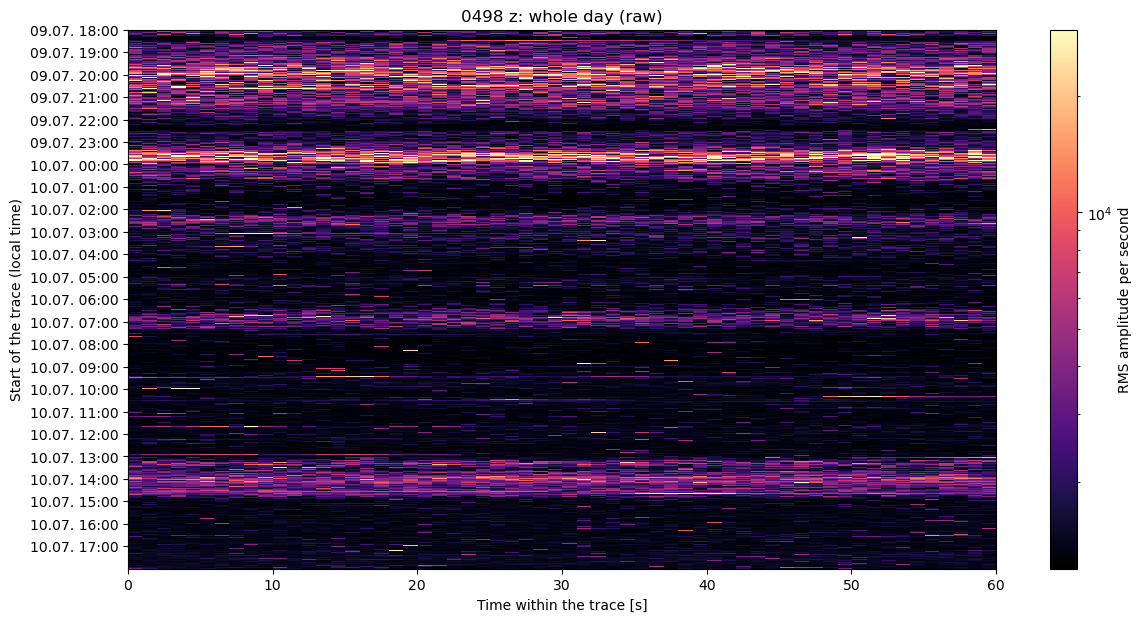

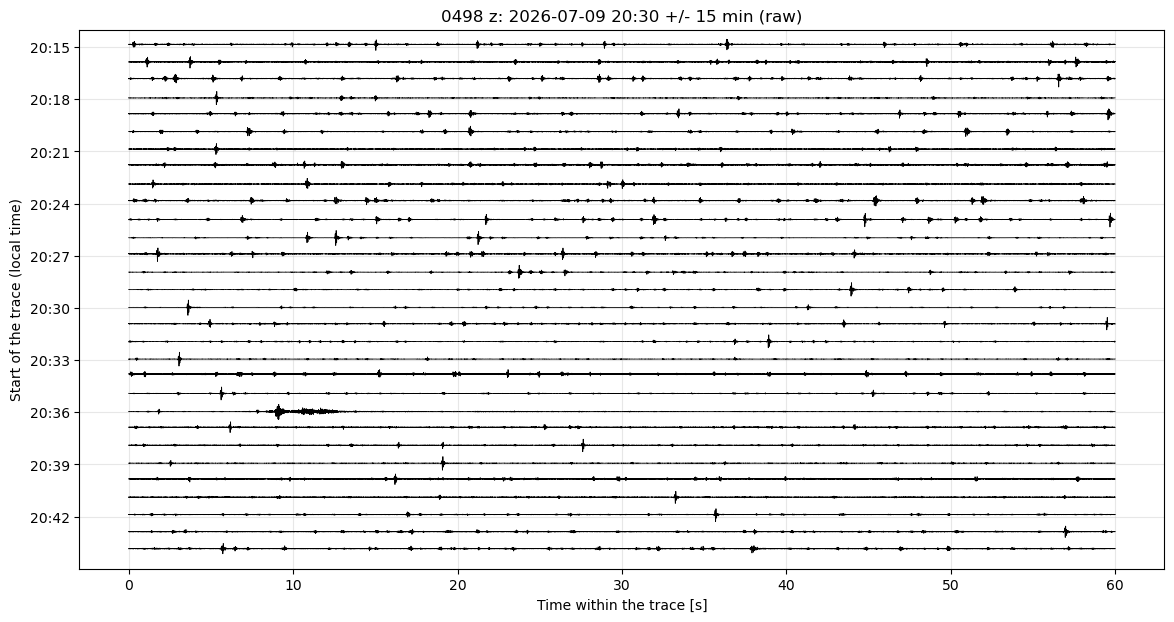

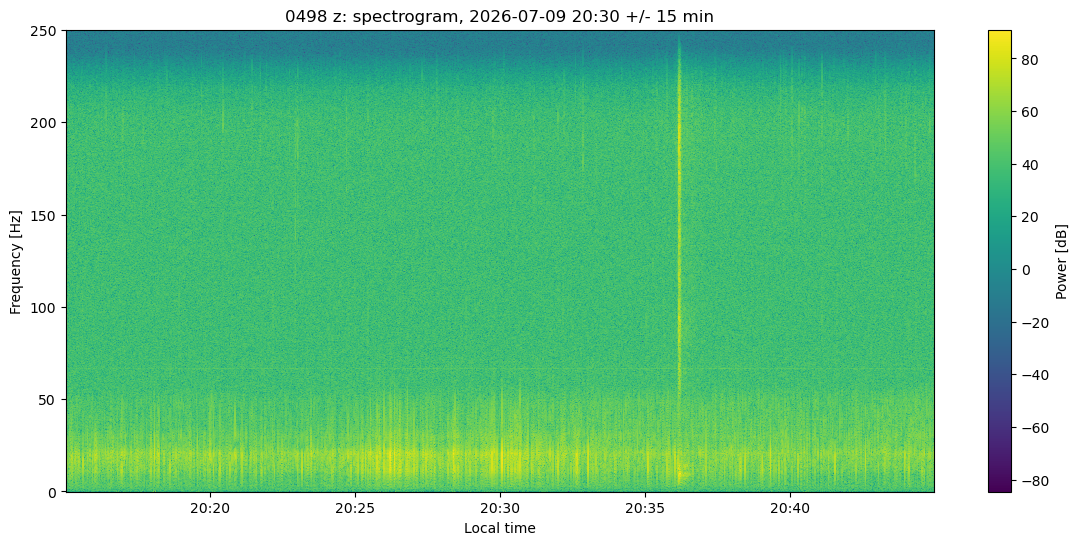

In [5]:
name = f"{STATION} {COMPONENT}"
raster_plot(data, dt, start_local, f"{name}: whole day (raw)")
wiggle_plot(data[zoom_first:zoom_last], dt, zoom_start_local, f"{name}: {TIME_LOCAL} +/- {ZOOM_MINUTES} min (raw)")
spectrogram_plot(data[zoom_first:zoom_last], dt, zoom_start_local, f"{name}: spectrogram, {TIME_LOCAL} +/- {ZOOM_MINUTES} min")

## 2. Bandpass filtered

The filter keeps only frequencies between `FILTER_HZ[0]` and `FILTER_HZ[1]`. It is applied to the whole day as one continuous signal, so there are no jumps at the trace boundaries. Change `FILTER_HZ` in the settings and run the cells below again to look at another frequency band.

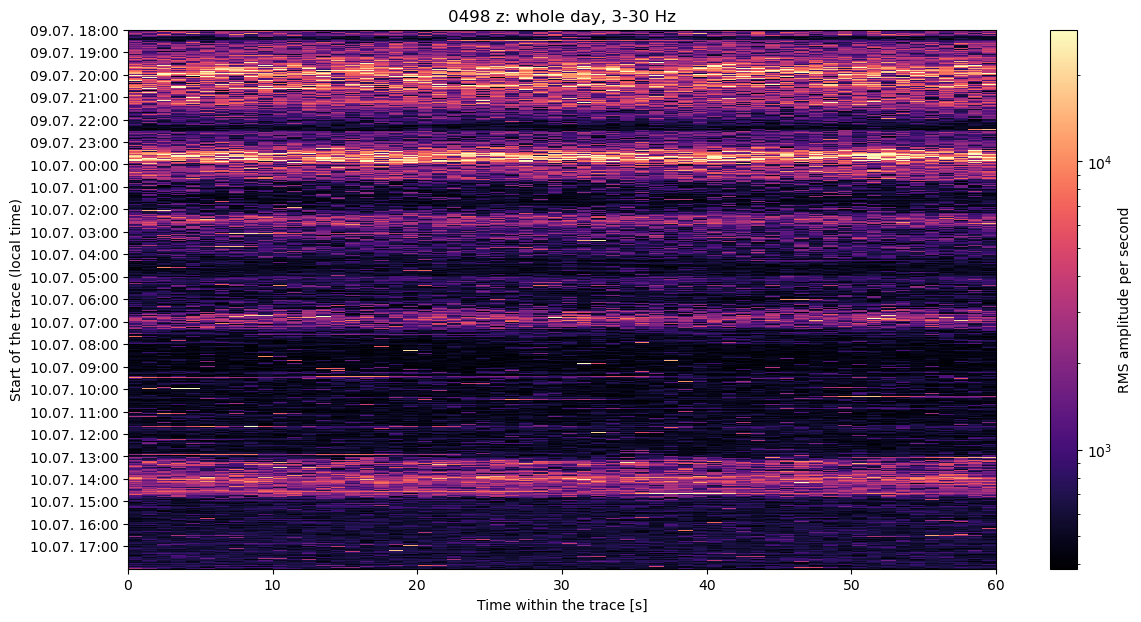

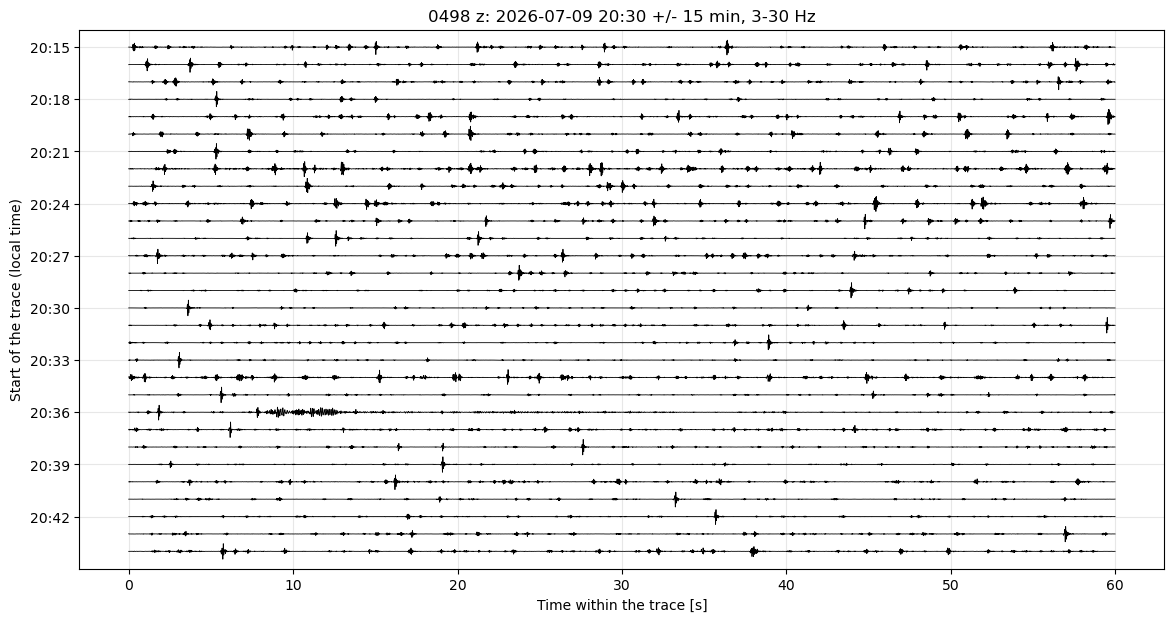

In [6]:
low, high = FILTER_HZ
sos = butter(4, [low, high], btype="bandpass", fs=1 / dt, output="sos")
filtered = sosfiltfilt(sos, data.reshape(-1).astype(np.float64)).reshape(data.shape).astype(np.float32)

raster_plot(filtered, dt, start_local, f"{name}: whole day, {low}-{high} Hz")
wiggle_plot(filtered[zoom_first:zoom_last], dt, zoom_start_local, f"{name}: {TIME_LOCAL} +/- {ZOOM_MINUTES} min, {low}-{high} Hz")